# Regresión: Ridge

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from ModeladoRegresion import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_REG, VARIANTES, N_ITER_REG, RUTA_FASE1_REG,
    cargar_split, separar_x_y_reg, crear_cv_reg, resumen_target, dispositivo_reg, describir_espacio_reg,
    ejecutar_fase1_reg, formatear_tabla_cv_reg, tabla_hiperparametros_reg, graficar_variantes, evaluar_smearing,
    elegir_variante, guardar_fase1_reg, formatear_hiperparametros,
)

CLAVE = "ridge"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_reg(CLAVE),
}, name=NOMBRES_REG[CLAVE]).to_frame()

,Ridge
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y_reg(df_train)
cv = crear_cv_reg(SEED)

resumen_target(y_train)

,Filas,Media,Mediana,DE,Asimetría,Ceros (%),BDI ≥ 14 (%)
Conjunto,,,,,,,
Train,3848,7.3,5.0,7.75,1.9,10.5,16.4


### Variantes del Target

| Variante | Qué se entrena | Cómo se predice |
|---|---|---|
| **a) Nativo** | `bdi_total` sin transformar (pérdida cuadrática) | Predicción directa |
| **b) sqrt** | $\sqrt{y}$ | $\hat y = \frac{1}{n}\sum_i (\hat z + e_i)^2$ (smearing) |
| **c) log1p** | $\log(1+y)$ | $\hat y = \frac{1}{n}\sum_i \left(e^{\hat z + e_i} - 1\right)$ (smearing) |

En las tres, la predicción final se recorta a $[0, 63]$.

**Sesgo de retransformación.** El modelo aprende la media **en la escala transformada**, $E[g(y)\mid x]$, y al deshacer la transformación se obtiene $g^{-1}(E[g(y)\mid x])$, que **no** es $E[y\mid x]$. Como las inversas ($z^2$ y $e^z - 1$) son convexas, por la desigualdad de Jensen la predicción retransformada **subestima la media** del BDI, más cuanto más dispersos son los residuos. Como el RMSE en puntos BDI premia acertar la media condicional, ese sesgo es un error sistemático.

**Corrección de smearing (Duan, 1983).** Se usan los residuos de entrenamiento en la escala transformada, $e_i = g(y_i) - \hat z_i$, como muestra de los errores posibles: $\hat y = \frac{1}{n}\sum_{i} g^{-1}(\hat z + e_i)$. `RegresorBDI` calcula los residuos **solo con los datos de entrenamiento de cada fold**. Todas las métricas se calculan en puntos BDI.

### Espacio de Búsqueda

Ridge encoge todos los coeficientes hacia 0 sin anularlos. Se exploraron 10 valores de `alpha` en escala logarítmica, desde casi sin penalización (1e-3, prácticamente OLS) hasta una penalización fuerte (1e3).

In [4]:
describir_espacio_reg(CLAVE).style.set_caption(f"Combinaciones por variante: {N_ITER_REG[CLAVE]}")

,Valores
Hiperparámetro,
alpha,log-uniforme entre 0.001 y 1000


### Validación Cruzada por Variante

Para cada variante se ejecuta un `RandomizedSearchCV` **solo sobre el train**, con los mismos folds y `scoring` RMSE (`neg_root_mean_squared_error`). El RMSE, el MAE y el R² se calculan siempre en puntos BDI, nunca en la escala transformada.

In [5]:
tabla, pipelines, hiperparametros = ejecutar_fase1_reg(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo             RMSE = 6.9000 ± 0.4862  R² = 0.2010  (4 s)
✓ sqrt + smearing    RMSE = 6.9347 ± 0.4750  R² = 0.1927  (1 s)
✓ log1p + smearing   RMSE = 7.0894 ± 0.4310  R² = 0.1549  (1 s)


In [6]:
vista = formatear_tabla_cv_reg(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=VARIANTES)

,RMSE,MAE,R²,Tiempo (s)
Variante,,,,
Nativo,6.900 ± 0.486,4.907 ± 0.188,0.201 ± 0.016,4.0
sqrt + smearing,6.935 ± 0.475,4.918 ± 0.191,0.193 ± 0.018,1.0
log1p + smearing,7.089 ± 0.431,4.977 ± 0.194,0.155 ± 0.035,1.0


El nativo obtiene el menor RMSE (6.900 ± 0.486) y el mayor R² (0.201 ± 0.016), prácticamente igual que la regresión lineal sin penalizar (6.900 ± 0.485). sqrt queda muy cerca (6.935, R² = 0.193) y log1p es la peor (7.089, R² = 0.155), aunque mejora a la regresión lineal en esa misma escala (7.254). El MAE sigue el mismo orden (4.907, 4.918 y 4.977).

In [7]:
# Mejores hiperparámetros por variante
tabla_hiperparametros_reg(hiperparametros)

,alpha
Variante,
Nativo,24.66
sqrt + smearing,17.72
log1p + smearing,506.20


El nativo y sqrt eligen penalizaciones moderadas (`alpha` = 24.7 y 17.7). Con 3,848 observaciones y 6 predictores, eso apenas encoge los coeficientes, así que Ridge reproduce a la regresión lineal. log1p elige una penalización mucho más fuerte (`alpha` = 506), que encoge bastante los coeficientes. Eso explica que mejore frente a OLS en esa escala, aunque siga siendo la peor variante.

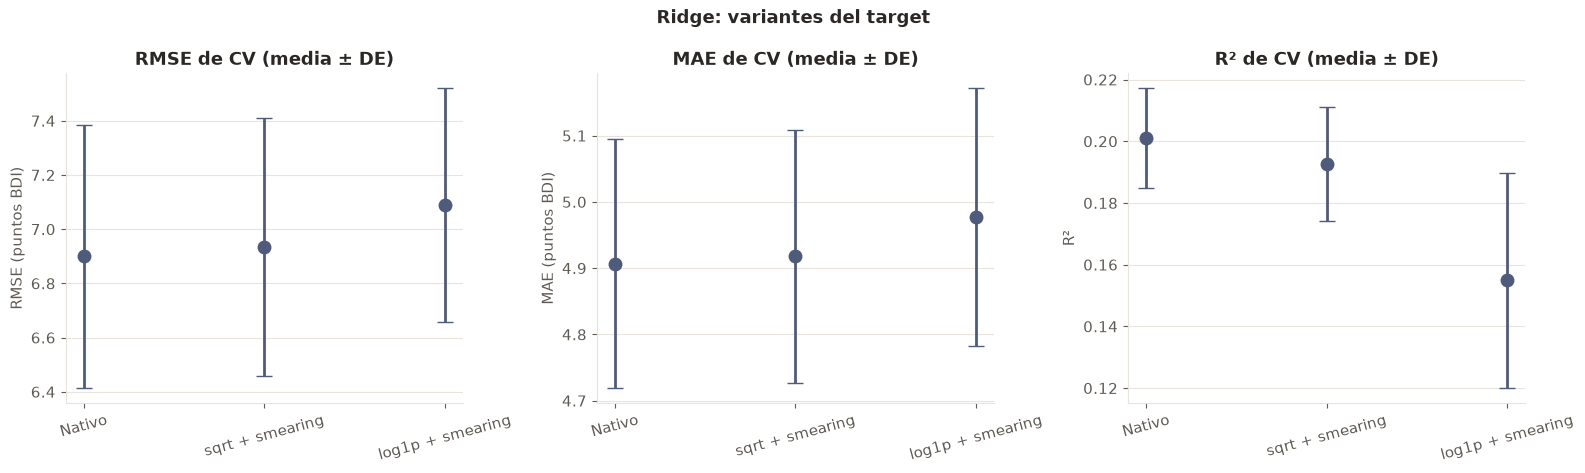

In [8]:
fig = graficar_variantes(tabla, NOMBRES_REG[CLAVE])
plt.show()

La gráfica confirma que el nativo y sqrt son equivalentes en las tres métricas, con barras de desviación que se solapan por completo, y que log1p es peor, con una caída del R² de unos 0.05.

### Sesgo de Retransformación: Efecto del Smearing

Con la mejor variante transformada se calculan predicciones *out-of-fold* (mismos folds, solo train) **con y sin** smearing. Sin la corrección, la media predicha debería quedar por debajo de la media real del BDI.

In [9]:
variante_t, tabla_smearing = evaluar_smearing(tabla, pipelines, X_train, y_train, cv)
tabla_smearing.round(3)

,Media,Sesgo medio,RMSE,MAE,R²
Out-of-fold (sqrt + smearing),,,,,
BDI real,7.302,0.000,NaN,NaN,NaN
Sin smearing,5.799,-1.503,7.112,4.672,0.157
Con smearing,7.280,-0.022,6.951,4.918,0.195


Sin smearing, la media predicha out-of-fold con sqrt es 5.80, 1.50 puntos por debajo de la media real (7.30). Ese es el sesgo de retransformación. Con la corrección, la media predicha queda en 7.28, el RMSE baja de 7.112 a 6.951 y el R² sube de 0.157 a 0.195.

El MAE, en cambio, empeora (de 4.672 a 4.918). Sin la corrección, la predicción se acerca a la mediana condicional, que es lo que minimiza el MAE en una distribución asimétrica. El smearing la lleva a la media, que es lo que minimiza el RMSE.

### Selección del Mejor Modelo Ridge

Se elige la variante con **menor RMSE medio de CV**.

**Regla de empate:** si una variante más simple (nativo < sqrt < log1p) queda a menos de una desviación estándar de CV de la ganadora, se elige la más simple.

In [10]:
variante_ganadora, explicacion = elegir_variante(tabla)

pd.Series({
    "Variante ganadora": VARIANTES[variante_ganadora],
    "RMSE de CV": f"{tabla.loc[variante_ganadora, 'RMSE media']:.4f} ± {tabla.loc[variante_ganadora, 'RMSE DE']:.4f}",
    "MAE de CV": f"{tabla.loc[variante_ganadora, 'MAE media']:.4f} ± {tabla.loc[variante_ganadora, 'MAE DE']:.4f}",
    "R² de CV": f"{tabla.loc[variante_ganadora, 'R² media']:.4f} ± {tabla.loc[variante_ganadora, 'R² DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[variante_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_REG[CLAVE]).to_frame()

,Ridge
Variante ganadora,Nativo
RMSE de CV,6.9000 ± 0.4862
MAE de CV,4.9069 ± 0.1878
R² de CV,0.2010 ± 0.0162
Hiperparámetros,alpha=24.66
Criterio,Se elige 'Nativo': tiene el menor RMSE medio de CV (6.9000 ± 0.4862) y ninguna opción más simple queda a menos de una desviación estándar (0.4862).


Gana la variante nativa por menor RMSE medio (6.9000), sin necesidad de la regla de empate. Con `alpha` = 24.66 es prácticamente la regresión lineal sin penalizar.

### Guardado

In [11]:
ganador = guardar_fase1_reg(
    CLAVE, tabla, variante_ganadora, pipelines[variante_ganadora],
    hiperparametros[variante_ganadora], explicacion,
)
print(f"✓ Guardado en {RUTA_FASE1_REG / CLAVE}: resultados_cv.csv, ganador.json y {ganador['archivo']}")

✓ Guardado en /workspace/data/processed/modelado/regresion/fase1/ridge: resultados_cv.csv, ganador.json y ridge_nativo.joblib
